# 01 · Exploratory data analysis — by persona category

**Dataset:** IBM Telco Customer Churn **v11.1.3** — 7,043 customers of a California telecom company, merged from five IBM tables (demographics, location, population, services, status). Names, emails and phone numbers are generated for display; they are never model inputs.

We look at churn through five lenses: **geographic, demographic, technographic, behavioural, psychographic**.

In [1]:
%matplotlib inline
import warnings, os
warnings.filterwarnings("ignore")
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from churnpulse import config
from churnpulse.dataset import load_customers
from churnpulse.features import FEATURE_CATEGORY, CATEGORIES
sns.set_theme(style="whitegrid", palette=["#0aa38a", "#f43f5e", "#f59e0b", "#6366f1", "#38bdf8"])
CAT_COLORS = {"geographic": "#38bdf8", "demographic": "#a78bfa", "technographic": "#22d3ee",
              "behavioural": "#fbbf24", "psychographic": "#f472b6"}
pd.set_option("display.max_columns", 50)


In [2]:
df = load_customers()
print(df.shape)
df.head(3).T

(7043, 40)


,0,1,2
customer_id,8779-QRDMV,7495-OOKFY,1658-BYGOY
name,Calvin Hawkins,Rose Lee,Alexander Fischer
email,calvin.hawkins92@example.net,rose.lee84@example.org,alexander.fischer33@example.com
phone,(409) 555-0179,(264) 555-0108,(622) 555-0111
city,Los Angeles,Los Angeles,Los Angeles
zip_code,90022,90063,90065
latitude,34.02381,34.044271,34.108833
longitude,-118.156582,-118.185237,-118.229715
population,68701,55668,47534
gender,Male,Female,Male


In [3]:
rate = df['churned'].mean()
print(f'Churn rate: {rate:.1%}  ({df.churned.sum():,} of {len(df):,} customers left)')

Churn rate: 26.5%  (1,869 of 7,043 customers left)


About **26.5%** left. Predicting "nobody leaves" already scores 73.5% accuracy, so ROC-AUC, recall and a business metric matter more than accuracy alone.

## 🌍 Geographic

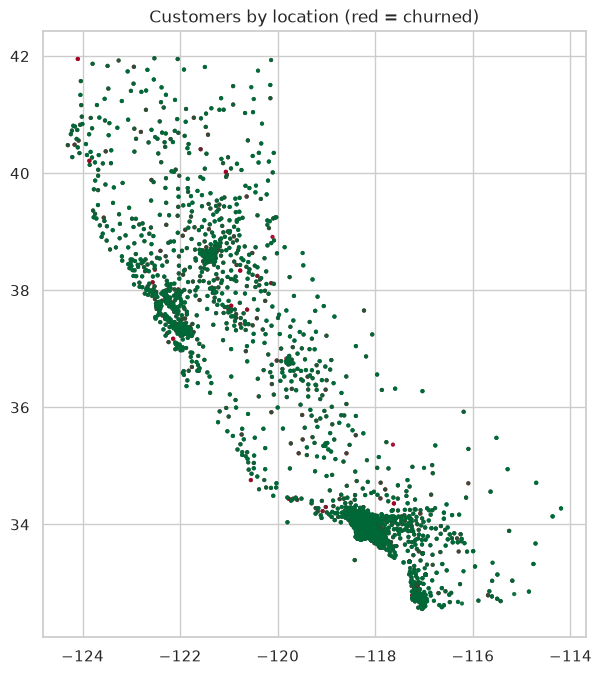

In [4]:
fig, ax = plt.subplots(figsize=(7, 8))
sc = ax.scatter(df.longitude, df.latitude, c=df.churned, cmap='RdYlGn_r', s=4, alpha=.6)
ax.set_title('Customers by location (red = churned)'); ax.set_aspect(1.2); plt.show()

In [5]:
city = df.groupby('city').agg(customers=('customer_id', 'size'), churn=('churned', 'mean')).query('customers >= 30')
city.sort_values('churn', ascending=False).head(10).style.format({'churn': '{:.0%}'})

,customers,churn
city,,
San Diego,285,65%
Fallbrook,43,60%
Temecula,38,58%
Glendale,40,32%
Escondido,51,31%
Pasadena,30,30%
San Francisco,104,30%
Berkeley,32,28%
Stockton,44,27%


Churn is spread across the state; some cities run hotter, but most have too few customers to learn from directly — so the model uses **latitude, longitude and area population** instead of the city name.

## 👥 Demographic

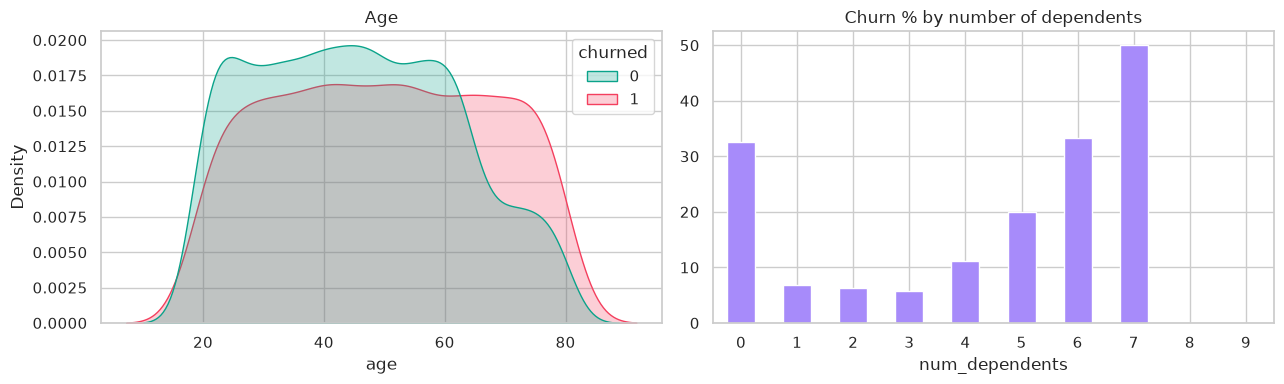

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.kdeplot(data=df, x='age', hue='churned', common_norm=False, fill=True, ax=axes[0]); axes[0].set_title('Age')
(df.groupby('num_dependents')['churned'].mean() * 100).plot.bar(ax=axes[1], color='#a78bfa', rot=0)
axes[1].set_title('Churn % by number of dependents'); plt.tight_layout(); plt.show()

Seniors churn more; customers **with dependents rarely leave** — one of the strongest demographic signals.

## 💻 Technographic

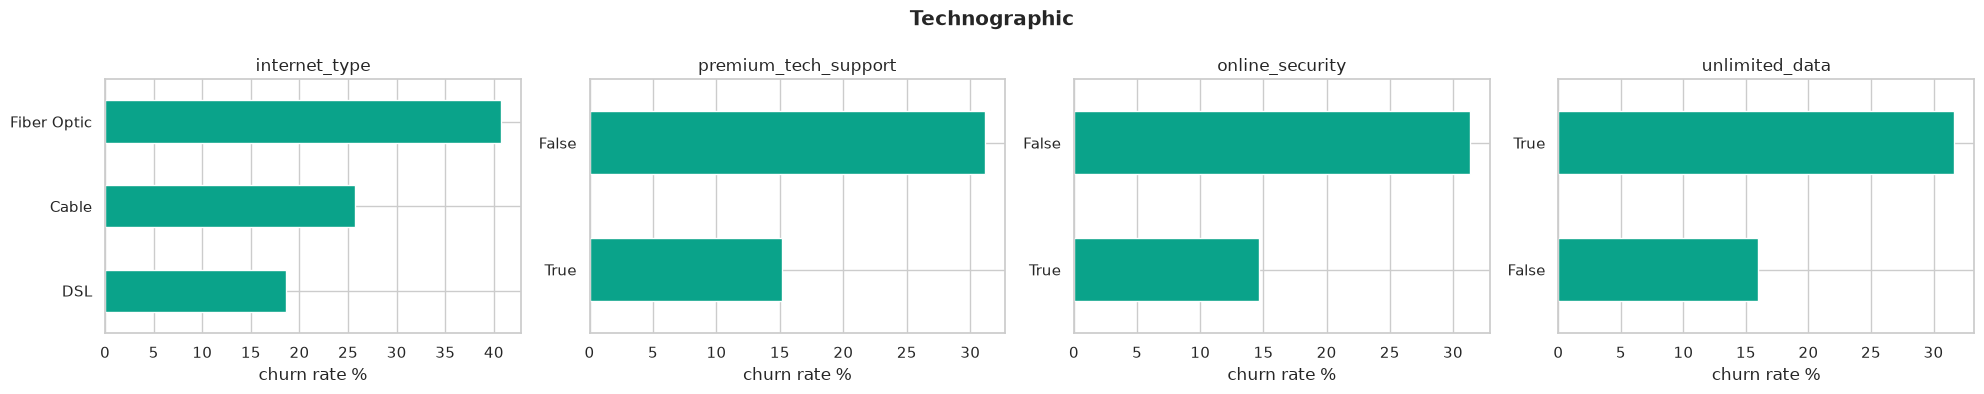

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(np.atleast_1d(axes), ['internet_type', 'premium_tech_support', 'online_security', 'unlimited_data']):
    (df.groupby(col)['churned'].mean().sort_values() * 100).plot.barh(ax=ax, color='#0aa38a')
    ax.set_title(col); ax.set_xlabel('churn rate %'); ax.set_ylabel('')
fig.suptitle('Technographic', fontweight='bold'); plt.tight_layout(); plt.show()

**Fiber optic** customers churn most, and those without tech support or security churn far more — they are paying for speed but not for help.

## 🔁 Behavioural

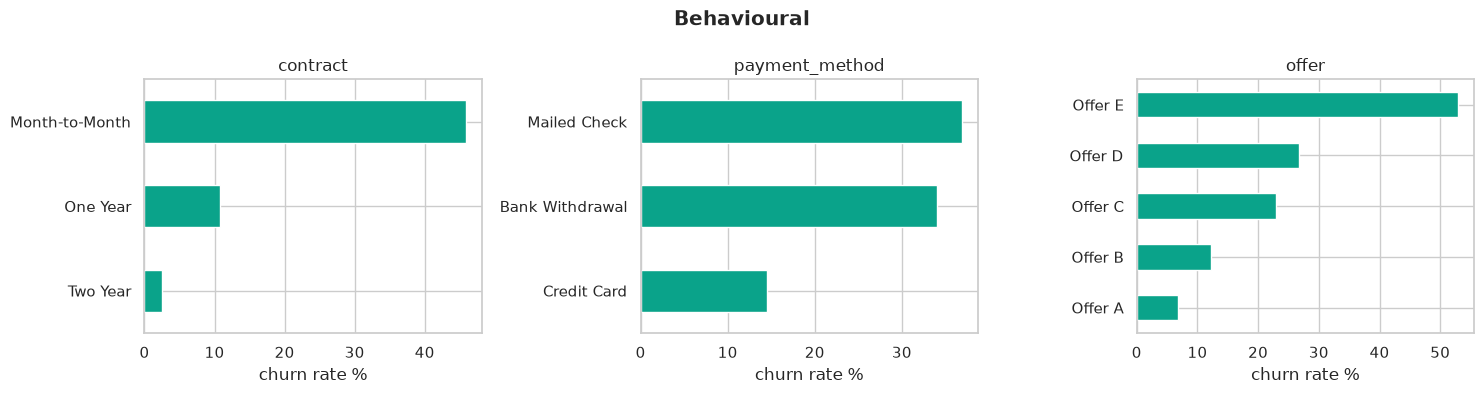

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(np.atleast_1d(axes), ['contract', 'payment_method', 'offer']):
    (df.groupby(col)['churned'].mean().sort_values() * 100).plot.barh(ax=ax, color='#0aa38a')
    ax.set_title(col); ax.set_xlabel('churn rate %'); ax.set_ylabel('')
fig.suptitle('Behavioural', fontweight='bold'); plt.tight_layout(); plt.show()

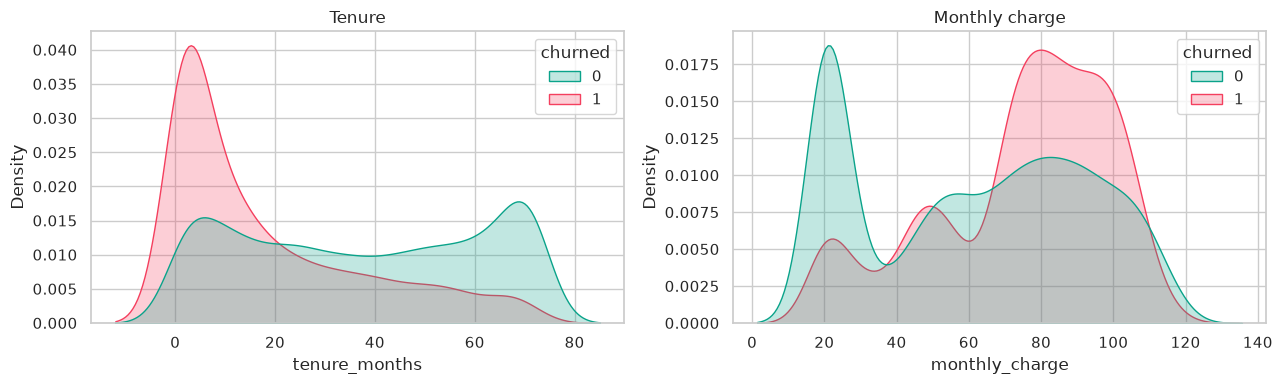

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.kdeplot(data=df, x='tenure_months', hue='churned', common_norm=False, fill=True, ax=axes[0]); axes[0].set_title('Tenure')
sns.kdeplot(data=df, x='monthly_charge', hue='churned', common_norm=False, fill=True, ax=axes[1]); axes[1].set_title('Monthly charge')
plt.tight_layout(); plt.show()

Month-to-month contracts, mailed checks, **Offer E** and the first months are high-risk.

## 🧠 Psychographic

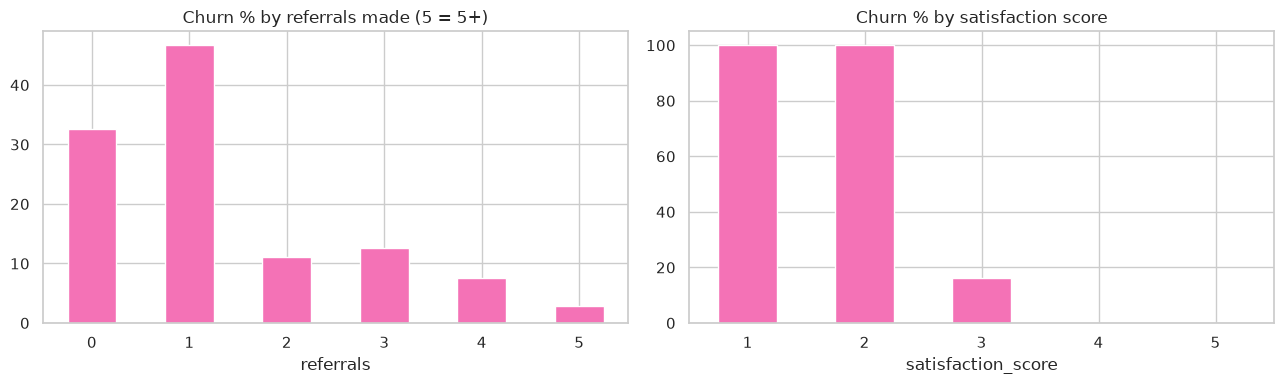

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
(df.groupby(df.referrals.clip(upper=5))['churned'].mean() * 100).plot.bar(ax=axes[0], color='#f472b6', rot=0)
axes[0].set_title('Churn % by referrals made (5 = 5+)')
(df.groupby('satisfaction_score')['churned'].mean() * 100).plot.bar(ax=axes[1], color='#f472b6', rot=0)
axes[1].set_title('Churn % by satisfaction score'); plt.tight_layout(); plt.show()

Customers who **refer friends** almost never leave (advocacy). Satisfaction separates churners *perfectly* — see the leakage analysis in notebook 03.